# 01 · La base de datos y las señales

**Pregunta de este notebook.** ¿Qué hay en la base Apnea-ECG, cómo se ven las señales y qué problemas tienen? De acá salen los requisitos del preprocesamiento (notebook `02`) y la idea que se pone a prueba en todo el trabajo.

**Hilo del trabajo.**
1. `01` — base de datos y exploración de las señales (este notebook).
2. `02` — filtro, latidos y serie RR.
3. `03` — latidos como realizaciones, filtro de Wiener y respiración derivada del ECG (EDR).
4. `04` — la feature, el umbral y la evaluación del detector.

**Hipótesis del trabajo.** Durante la apnea, la frecuencia cardíaca y la respiración oscilan juntas al ritmo del ciclo apnea–recuperación. Por eso, en los minutos con apnea, la potencia que comparten la serie RR y la EDR en la banda lenta (0,01–0,05 Hz) es mayor que en los minutos normales, y alcanza para clasificar cada minuto con un único umbral.

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.signal import spectrogram, welch

from src.config import SPLIT_CSV
from src.features.edr import compute_edr
from src.data import (load_apnea_labels, load_ecg, load_ecg_digital, load_header, load_qrs,
                      load_record_info, load_respiration)
from src.preprocessing.quality import flat_mask, saturated_mask
from src.qrs.rr_clean import clean_rr
from src.viz.plots import (ANCHO, APNEA, COLORES_CAT, GRIS, NORMAL, label_strip, save, setup,
                           shade_apnea)

setup()
split = pd.read_csv(SPLIT_CSV)
info = load_record_info()
base = split.merge(info[["record", "AHI", "AI", "HI", "age", "sex", "height_cm", "weight_kg"]], on="record")

## 1. Qué es la base

La **Apnea-ECG Database** (Penzel et al., 2000; PhysioNet) se armó para el *PhysioNet/Computers in Cardiology Challenge 2000*. Tiene 70 registros nocturnos de 7 a 10 horas con:

- **ECG de una derivación**, muestreado a **100 Hz** con un conversor de 12 bits.
- **Una etiqueta por minuto** (apnea o normal), asignada por un experto mirando la respiración y la saturación de oxígeno de la polisomnografía. Un minuto se marca como apnea si en él hay una apnea o una hipopnea.
- En 8 registros (a01–a04, b01, c01–c03), además, la **respiración** medida (bandas de tórax y abdomen, flujo nasal y SpO2). La usamos solo para validar la respiración derivada del ECG.
- Edad, sexo, altura, peso y el índice de apnea-hipopnea (AHI) de cada registro.

### Las categorías A, B y C

PhysioNet agrupa los registros según cuánta apnea tienen. La categoría **no** describe a la persona sino a la noche:

| Categoría | Criterio de PhysioNet |
|---|---|
| **A** (apnea) | al menos una hora con índice de apnea ≥ 10 **y** al menos 100 minutos con apnea en la noche |
| **B** (límite) | al menos una hora con índice de apnea ≥ 5 **y** entre 5 y 99 minutos con apnea |
| **C** (control) | menos de 5 minutos con apnea |

La figura muestra la regla: el eje horizontal es la cantidad de minutos con apnea de cada noche y el vertical, el AHI.

,registros,AHI_mediana,AHI_min,AHI_max,pct_apnea_mediana
category,,,,,
A,40,41.5,14.00,93.50,62.6
B,10,7.5,0.13,33.00,11.7
C,17,0.0,0.00,0.38,0.2


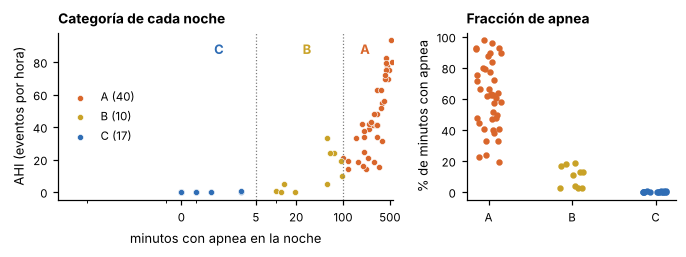

In [2]:
fig, ax = plt.subplots(1, 2, figsize=(ANCHO, 2.4), gridspec_kw={"width_ratios": [1.6, 1]})
for cat, g in base.groupby("category"):
    ax[0].scatter(g.apnea_minutes, g.AHI, s=16, color=COLORES_CAT[cat], label=f"{cat} ({len(g)})",
                  edgecolor="white", lw=0.4)
for x in (5, 100):
    ax[0].axvline(x, color=GRIS, ls=":", lw=0.8)
ax[0].set_xscale("symlog", linthresh=5)
ax[0].set_xticks([0, 5, 20, 100, 500]); ax[0].set_xticklabels([0, 5, 20, 100, 500])
ax[0].set(xlabel="minutos con apnea en la noche", ylabel="AHI (eventos por hora)",
          title="Categoría de cada noche")
ax[0].text(2.2, 85, "C", color=COLORES_CAT["C"], fontweight="bold")
ax[0].text(25, 85, "B", color=COLORES_CAT["B"], fontweight="bold")
ax[0].text(180, 85, "A", color=COLORES_CAT["A"], fontweight="bold")
ax[0].legend(loc="center left")
frac = base.assign(f=base.apnea_minutes / base.n_minutes)
for i, cat in enumerate("ABC"):
    v = frac.loc[frac.category == cat, "f"]
    ax[1].scatter(np.full(len(v), i) + np.random.default_rng(0).uniform(-0.15, 0.15, len(v)), 100 * v,
                  s=10, color=COLORES_CAT[cat])
ax[1].set_xticks([0, 1, 2]); ax[1].set_xticklabels(["A", "B", "C"])
ax[1].set(ylabel="% de minutos con apnea", title="Fracción de apnea")
fig.tight_layout()
save(fig, "01_categorias")
(frac.groupby("category").agg(registros=("record", "size"), AHI_mediana=("AHI", "median"),
                              AHI_min=("AHI", "min"), AHI_max=("AHI", "max"),
                              pct_apnea_mediana=("f", lambda v: round(100 * v.median(), 1))))

**Qué se ve.** Las tres categorías quedan separadas por los cortes de 5 y 100 minutos. En las noches A la mayoría de los minutos tienen apnea; en las C, casi ninguno. Eso hace que en la base haya **noches enteras de apnea y noches enteras normales**, algo a tener en cuenta al evaluar: un detector que solo reconozca a la persona (y no al minuto) parecería funcionar bien.

## 2. Registros, sujetos y partición

La base no identifica a las personas, pero hay registros de la misma persona en noches distintas (mismo perfil de edad, sexo, altura y peso, y latido casi idéntico) y tres pares de registros que son **la misma grabación** con un desfase de segundos (c05/c06, x22/x35, x33/x34). El análisis está en `notebooks/v1/01_verificacion_sujetos.ipynb`. Se excluye un registro de cada par: quedan **67 registros de 29 sujetos**.

**Por qué partir por sujeto.** Los minutos de una persona se parecen entre sí más que a los de otra. Si un sujeto tuviera noches en desarrollo y en test, el umbral se ajustaría con datos de la misma persona con la que después se evalúa y el resultado saldría optimista.

**Cómo se partió** (`src/split.py`, semilla 2026):
1. Se agrupan los registros por sujeto.
2. Los sujetos con respiración registrada van a desarrollo (se necesitan para validar la EDR).
3. Se sortean los demás sujetos para que test tenga ~30 % de los registros, con las mismas proporciones de A, B y C que la base, y con una fracción de minutos con apnea que no difiera más de 2 puntos de la de desarrollo.

In [3]:
tab = (split.groupby(["set", "category"]).size().unstack(fill_value=0)
       .join(split.groupby("set").agg(registros=("record", "size"), sujetos=("subject", "nunique"),
                                      minutos=("n_minutes", "sum"), minutos_apnea=("apnea_minutes", "sum"))))
tab["% apnea"] = (100 * tab.minutos_apnea / tab.minutos).round(1)
tab

,A,B,C,registros,sujetos,minutos,minutos_apnea,% apnea
set,,,,,,,,
dev,28,7,12,47,19,23138,9218,39.8
test,12,3,5,20,10,9754,3838,39.3


**Qué se usa de cada conjunto.** En **desarrollo** (47 registros, 19 sujetos) se miran las señales, se diseña el preprocesamiento y se elige el umbral. **Test** (20 registros, 10 sujetos) solo se usa para medir el detector terminado.

## 3. Cómo se ven las señales

Antes de procesar hay que mirar. La figura muestra 8 s de ECG crudo de cinco registros, elegidos porque ilustran los problemas que aparecen en la base.

PosixPath('/home/user/TP-PSB-G8/informe/figuras/01_ejemplos_ecg.png')

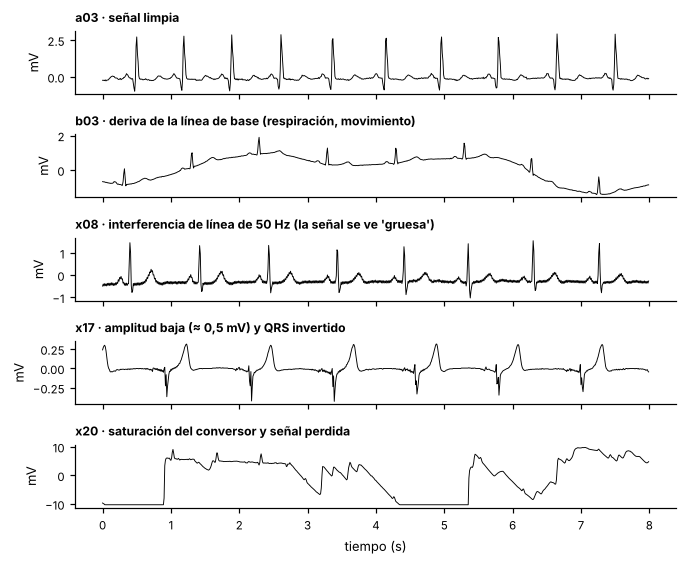

In [4]:
def ventana(rec, t0, dur=8):
    ecg, fs = load_ecg(rec)
    i = int(t0 * fs)
    return np.arange(int(dur * fs)) / fs, ecg[i:i + int(dur * fs)]

ejemplos = [
    ("a03", 3600, "a03 · señal limpia"),
    ("b03", 3*3600 + 600, "b03 · deriva de la línea de base (respiración, movimiento)"),
    ("x08", 2*3600, "x08 · interferencia de línea de 50 Hz (la señal se ve 'gruesa')"),
    ("x17", 2*3600, "x17 · amplitud baja (≈ 0,5 mV) y QRS invertido"),
    ("x20", 163.17 * 60 - 4, "x20 · saturación del conversor y señal perdida"),
]
fig, axs = plt.subplots(len(ejemplos), 1, figsize=(ANCHO, 5.2), sharex=True)
for ax, (rec, t0, titulo) in zip(axs, ejemplos):
    t, x = ventana(rec, t0)
    ax.plot(t, x, color="black", lw=0.6)
    ax.set_title(titulo, fontsize=8)
    ax.set_ylabel("mV")
axs[-1].set_xlabel("tiempo (s)")
fig.tight_layout()
save(fig, "01_ejemplos_ecg")

**Qué se ve.**
- **a03**: los complejos QRS se distinguen con claridad; las ondas P y T también.
- **b03**: el nivel de la señal sube y baja lentamente (deriva de la línea de base). Mueve la amplitud aparente de cada latido y molesta para medir el QRS.
- **x08**: hay una oscilación rápida superpuesta a todo el registro. A 100 Hz de muestreo, la frecuencia de Nyquist es justo 50 Hz, la frecuencia de la red eléctrica en Alemania, donde se grabó la base: la interferencia aparece como una alternancia muestra a muestra.
- **x17**: el QRS mide ~0,5 mV pico a pico y apunta hacia abajo (la polaridad depende de dónde quedaron los electrodos). El detector de latidos tiene que funcionar con las dos polaridades y con amplitudes chicas.
- **x20**: la señal toca el tope del conversor (−10 mV) y queda plana: electrodo despegado o movimiento. En esos tramos no hay latidos que detectar.

Los mismos problemas se ven en frecuencia, y ahí se pueden medir en todos los registros.

## 4. Las señales en frecuencia

Se calcula la densidad espectral de potencia (PSD) de cada registro de desarrollo con el método de Welch (segmentos de 4096 muestras, ≈ 41 s, resolución de 0,024 Hz), normalizada a potencia total 1 para que todos los registros pesen igual. También se calcula el espectro del **latido** mediano de cada registro (de −250 a +400 ms alrededor de cada marca de QRS): es la parte de la señal que interesa conservar.

In [5]:
dev = split[split.set == "dev"].record.tolist()
psds, beats, filas = [], [], []
for rec in split.record:
    ecg, fs = load_ecg(rec)
    d = load_ecg_digital(rec); h = load_header(rec)
    f, p = welch(ecg - ecg.mean(), fs=fs, nperseg=4096)
    p = p / np.trapezoid(p, f)
    qrs = load_qrs(rec)
    _, rr, corr = clean_rr(qrs / fs)
    banda = lambda a, b: float(np.trapezoid(p[(f >= a) & (f < b)], f[(f >= a) & (f < b)]))
    alt = (ecg[:-1:2] - ecg[1::2]) / 2                   # componente que alterna muestra a muestra (50 Hz)
    perdida = flat_mask(d, fs) | saturated_mask(d - h["cero"], h["bits"])
    filas.append({"record": rec, "pot_bajo_0.5Hz": banda(0, 0.5), "pot_40_50Hz": banda(40, 50.01),
                  "pico_50Hz": float(p[-1] / np.median(p[(f > 45) & (f < 49)])),
                  "amplitud_mV": float(np.percentile(ecg, 99) - np.percentile(ecg, 1)),
                  "senal_perdida_pct": 100 * float(perdida.mean()),
                  "rr_corregidos_pct": 100 * float(corr.mean()),
                  "fc_lpm": 60 / float(np.median(rr))})
    if rec in dev:
        psds.append(p)
        a, b = 25, 40
        pk = qrs[(qrs > a) & (qrs < len(ecg) - b)]
        beat = np.median(ecg[pk[:, None] + np.arange(-a, b)], axis=0)
        beat = beat - np.median(beat)
        fb = np.fft.rfftfreq(1024, 1 / fs)
        pb = np.abs(np.fft.rfft(beat, 1024)) ** 2
        beats.append(pb / np.trapezoid(pb, fb))
        filas[-1]["f99_latido_Hz"] = float(fb[np.searchsorted(np.cumsum(pb) / pb.sum(), 0.99)])
psds, beats = np.array(psds), np.array(beats)
calidad = pd.DataFrame(filas).merge(split[["record", "set", "category"]])

PosixPath('/home/user/TP-PSB-G8/informe/figuras/01_espectro_ecg.png')

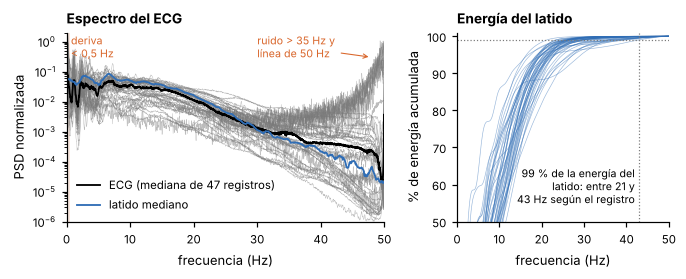

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(ANCHO, 2.6), gridspec_kw={"width_ratios": [1.5, 1]})
for p in psds:
    ax[0].semilogy(f, p, color=GRIS, lw=0.3, alpha=0.5)
ax[0].semilogy(f, np.median(psds, axis=0), color="black", lw=1.2, label="ECG (mediana de 47 registros)")
ax[0].semilogy(fb, np.median(beats, axis=0), color=NORMAL, lw=1.2, label="latido mediano")
ax[0].axvspan(0, 0.5, color=APNEA, alpha=0.15, lw=0)
ax[0].text(0.7, 3e-1, "deriva\n< 0,5 Hz", fontsize=7, color=APNEA)
ax[0].annotate("ruido > 35 Hz y\nlínea de 50 Hz", xy=(48, 3e-1), xytext=(30, 3e-1),
               fontsize=7, color=APNEA, arrowprops=dict(arrowstyle="->", color=APNEA, lw=0.7))
ax[0].set(xlabel="frecuencia (Hz)", ylabel="PSD normalizada", title="Espectro del ECG", xlim=(0, 50),
          ylim=(1e-6, 2))
ax[0].legend(loc="lower left")
for pb in beats:
    c = np.cumsum(pb); ax[1].plot(fb, 100 * c / c[-1], color=NORMAL, lw=0.4, alpha=0.5)
f99 = calidad.loc[calidad.set == "dev", "f99_latido_Hz"]
ax[1].axhline(99, color=GRIS, ls=":", lw=0.8); ax[1].axvline(f99.max(), color=GRIS, ls=":", lw=0.8)
ax[1].text(f99.max() - 1, 55, f"99 % de la energía del\nlatido: entre {f99.min():.0f} y\n{f99.max():.0f} Hz según el registro",
           fontsize=7, ha="right")
ax[1].set_ylim(50, 101)
ax[1].set(xlabel="frecuencia (Hz)", ylabel="% de energía acumulada", title="Energía del latido", xlim=(0, 50))
fig.tight_layout()
save(fig, "01_espectro_ecg")

**Qué se ve.**
- Por debajo de 0,5 Hz hay mucha potencia que no pertenece al latido (el latido mediano casi no tiene energía ahí): es la **deriva de la línea de base**.
- La energía del latido está entre ~1 y ~40 Hz. A la derecha, la energía acumulada del latido de cada registro: el 99 % queda por debajo de una frecuencia que va de 21 a 43 Hz según el registro.
- En varios registros la potencia vuelve a subir por encima de ~35 Hz y hay un **pico** en el último punto del espectro (50 Hz): ruido de alta frecuencia e interferencia de la red. Como cae justo en Nyquist, no se puede separar del latido con un filtro angosto (notch) sin dañar la señal cerca de 50 Hz, pero sí con un pasabajos por debajo de esa frecuencia, porque el latido casi no tiene energía arriba de 40 Hz.

El espectro tiene la **misma forma en todos los registros** (curvas grises): cambia cuánto pesan la deriva y la interferencia, no dónde están. Eso justifica aplicar el **mismo filtro a todos los registros**. Cuánto pesa cada problema en cada registro se mide abajo.

registros con >10 % de potencia bajo 0,5 Hz         25
registros con pico de 50 Hz (>10 veces el fondo)    33
registros con >1 % de señal perdida                 13
registros con >10 % de RR corregidos                 5
registros                                           67
dtype: int64

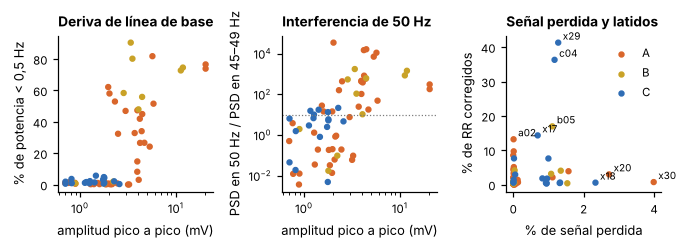

In [7]:
fig, axs = plt.subplots(1, 3, figsize=(ANCHO, 2.3))
orden = calidad.sort_values("category")
colores = orden.category.map(COLORES_CAT)
axs[0].scatter(orden.amplitud_mV, 100 * orden["pot_bajo_0.5Hz"], s=10, c=colores)
axs[0].set(xscale="log", xlabel="amplitud pico a pico (mV)", ylabel="% de potencia < 0,5 Hz",
           title="Deriva de línea de base")
axs[1].scatter(orden.amplitud_mV, orden["pico_50Hz"], s=10, c=colores)
axs[1].set(xscale="log", yscale="log", xlabel="amplitud pico a pico (mV)",
           ylabel="PSD en 50 Hz / PSD en 45–49 Hz", title="Interferencia de 50 Hz")
axs[1].axhline(10, color=GRIS, ls=":", lw=0.8)
axs[2].scatter(orden.senal_perdida_pct, orden.rr_corregidos_pct, s=10, c=colores)
axs[2].set(xlabel="% de señal perdida", ylabel="% de RR corregidos", title="Señal perdida y latidos")
for _, r in orden[(orden.rr_corregidos_pct > 10) | (orden.senal_perdida_pct > 2)].iterrows():
    axs[2].annotate(r.record, (r.senal_perdida_pct, r.rr_corregidos_pct), fontsize=6.5,
                    xytext=(3, 2), textcoords="offset points")
for cat in "ABC":
    axs[2].scatter([], [], s=10, color=COLORES_CAT[cat], label=cat)
axs[2].legend(loc="upper right")
fig.tight_layout()
save(fig, "01_calidad")
resumen = pd.Series({
    "registros con >10 % de potencia bajo 0,5 Hz": int((calidad["pot_bajo_0.5Hz"] > 0.10).sum()),
    "registros con pico de 50 Hz (>10 veces el fondo)": int((calidad["pico_50Hz"] > 10).sum()),
    "registros con >1 % de señal perdida": int((calidad.senal_perdida_pct > 1).sum()),
    "registros con >10 % de RR corregidos": int((calidad.rr_corregidos_pct > 10).sum()),
    "registros": len(calidad),
})
resumen

**Qué se ve.** La deriva y la interferencia de 50 Hz son frecuentes, no casos aislados: 25 de los 67 registros tienen más del 10 % de su potencia por debajo de 0,5 Hz y 33 tienen un pico en 50 Hz. La deriva fuerte aparece en los registros de mayor amplitud. La señal perdida es poca (menos del 4 % de cada registro) y suele aparecer al final de la noche, cuando se retiran los electrodos. Los registros con muchos RR corregidos (`a02`, `c04`, `x17`, `x29`) son de amplitud baja, donde a las marcas de QRS de la base les cuesta más; la corrección de RR se trata en `02`.

### La noche entera de un registro

El espectrograma muestra cómo cambia el espectro a lo largo de la noche. Se calcula con ventanas de 30 s (resolución de 0,033 Hz). Abajo, la franja con las etiquetas de cada minuto.

PosixPath('/home/user/TP-PSB-G8/informe/figuras/01_espectrograma_ecg.png')

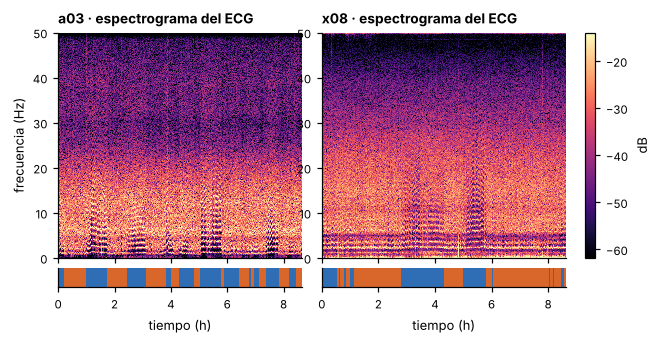

In [8]:
fig, axs = plt.subplots(2, 3, figsize=(ANCHO, 3.0), sharex="col",
                        gridspec_kw={"height_ratios": [6, 0.5], "width_ratios": [1, 1, 0.04],
                                     "hspace": 0.08, "wspace": 0.12})
for j, rec in enumerate(["a03", "x08"]):
    ecg, fs = load_ecg(rec)
    fe, te, S = spectrogram(ecg - ecg.mean(), fs=fs, nperseg=3000, noverlap=1500)
    im = axs[0, j].pcolormesh(te / 3600, fe, 10 * np.log10(S + 1e-12), shading="auto", cmap="magma",
                              vmin=np.percentile(10 * np.log10(S + 1e-12), 5),
                              vmax=np.percentile(10 * np.log10(S + 1e-12), 99.5), rasterized=True)
    axs[0, j].set(title=f"{rec} · espectrograma del ECG", ylabel="frecuencia (Hz)" if j == 0 else None)
    label_strip(axs[1, j], load_apnea_labels(rec), unit=60)
    axs[1, j].set_xlabel("tiempo (h)")
fig.colorbar(im, cax=axs[0, 2], label="dB")
axs[1, 2].axis("off")
save(fig, "01_espectrograma_ecg")

**Qué se ve.**
- En los dos registros la energía está entre ~1 y 40 Hz toda la noche; las franjas verticales breves son movimientos. En `x08` se ve además la línea de 50 Hz en el borde superior.
- En los tramos **normales** (azul) aparecen **líneas horizontales finas y paralelas**: son los armónicos de la frecuencia cardíaca (el ECG es casi periódico). Son nítidas porque la frecuencia cardíaca se mantiene estable durante minutos.
- Durante la **apnea** (naranja) esas líneas se borronean: la frecuencia cardíaca cambia de un latido a otro, con cada ciclo de apnea, y sus armónicos se desparraman.

Es decir, la apnea casi no cambia la forma de cada latido, pero sí **cómo varía el ritmo a lo largo del tiempo**. Para medirlo directamente hay que pasar del ECG a series latido a latido: el intervalo RR y el área del QRS.

## 5. Qué cambia con la apnea

Se comparan 5 minutos con apnea y 5 minutos normales del mismo registro (`a03`), con la respiración medida como referencia. Para cada latido (marcas de QRS de la base) se calculan el intervalo RR y el **área del QRS** (área con signo en ±60 ms alrededor del pico, sobre el ECG filtrado). El área cambia con la respiración porque el tórax se llena y se vacía y el eje eléctrico del corazón se mueve respecto de los electrodos; en `03` se explica y se valida contra la respiración medida.

PosixPath('/home/user/TP-PSB-G8/informe/figuras/01_apnea_vs_normal.png')

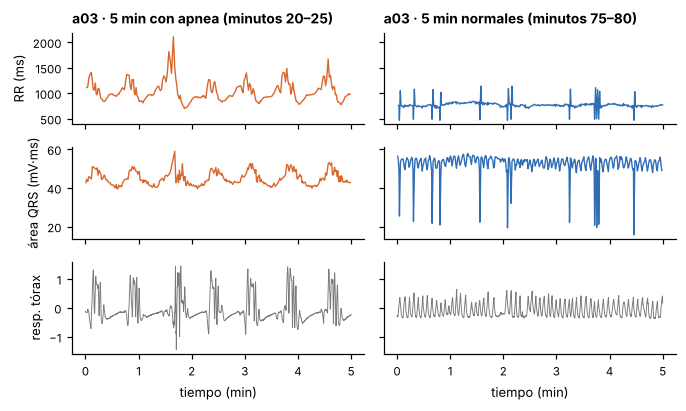

In [9]:
rec = "a03"
ecg, fs = load_ecg(rec)
qrs = load_qrs(rec)
resp, fs_r = load_respiration(rec)
lab = load_apnea_labels(rec)
t_edr, area = compute_edr(ecg, qrs, fs, "area")   # área del QRS de cada latido (ver 03)
t_q = qrs / fs

fig, axs = plt.subplots(3, 2, figsize=(ANCHO, 3.8), sharex="col", sharey="row")
for j, (m0, titulo, color) in enumerate([(20, "5 min con apnea", APNEA), (75, "5 min normales", NORMAL)]):
    sel = (t_q >= 60 * m0) & (t_q < 60 * (m0 + 5))
    tt = t_q[sel] / 60 - m0
    axs[0, j].plot(tt[1:], 1000 * np.diff(t_q[sel]), color=color)
    se = (t_edr >= 60 * m0) & (t_edr < 60 * (m0 + 5))
    axs[1, j].plot(t_edr[se] / 60 - m0, 1000 * area[se], color=color)
    i0, i1 = int(60 * m0 * fs_r), int(60 * (m0 + 5) * fs_r)
    axs[2, j].plot(np.arange(i1 - i0) / fs_r / 60, resp["Resp C"][i0:i1], color=GRIS, lw=0.6)
    axs[0, j].set_title(f"{rec} · {titulo} (minutos {m0}–{m0 + 5})")
    axs[2, j].set_xlabel("tiempo (min)")
axs[0, 0].set_ylabel("RR (ms)"); axs[1, 0].set_ylabel("área QRS (mV·ms)"); axs[2, 0].set_ylabel("resp. tórax")
fig.tight_layout()
save(fig, "01_apnea_vs_normal")

**Qué se ve.**
- **Durante la apnea** la respiración se interrumpe y se reanuda cada ~30–60 s. Con cada ciclo, el RR sube (la frecuencia cardíaca baja durante la pausa) y baja bruscamente cuando se reanuda la respiración: es la **variación cíclica de la frecuencia cardíaca** descripta por Guilleminault et al. (1984). El área del QRS también oscila con el mismo ritmo: sube y baja junto con la respiración, que se detiene y se reanuda.
- **En los minutos normales** el RR y el área del QRS oscilan con la respiración (~4 s por ciclo, 0,25 Hz) y no hay una oscilación lenta compartida. Los picos aislados son latidos ectópicos: en el RR dejan un intervalo corto seguido de uno largo y en el área un valle, porque el latido tiene otra forma. Se corrigen en `02` y `03`.

Entonces la apnea deja una **oscilación lenta, de período entre ~20 y 100 s (0,01–0,05 Hz), común a la serie RR y a la amplitud del QRS**. La serie RR se obtiene detectando los latidos (`02`); la amplitud o el área del QRS a lo largo del tiempo es la respiración derivada del ECG, EDR (`03`). En `04` se mide esa oscilación compartida en todos los minutos.

## 6. Qué se lleva el preprocesamiento

| Observación | Requisito |
|---|---|
| Deriva de línea de base por debajo de 0,5 Hz en muchos registros | pasaaltos que la saque sin tocar el latido (el ritmo cardíaco más lento, ~0,8 Hz) |
| Interferencia de 50 Hz en Nyquist; el 99 % de la energía del latido está por debajo de ~40 Hz | pasabajos entre 40 y 50 Hz |
| Misma forma espectral en todos los registros | un único filtro para todos |
| A 100 Hz el pico R cae en una grilla de 10 ms | refinar la posición del pico (`02`) |
| Registros de amplitud baja y tramos perdidos | detectar latidos de forma robusta y corregir los RR imposibles (`02`) |
| La apnea aparece en la variación lenta y compartida de RR y amplitud del QRS | serie RR (`02`), EDR (`03`) y su potencia compartida en 0,01–0,05 Hz (`04`) |